# Floyd–Warshall: CPU, CUDA e multi-stage

Confrontiamo CPU standard, CPU blocked, GPU standard, GPU blocked a tre fasi e una variante GPU multi-stage ispirata a Lund e Smith.

La variante multi-stage è didattica: usa tile 16×16; in fase 3 carica le dipendenze in fette di quattro valori di $k$ e mantiene quattro celle di uscita per thread nei registri. **Non** riproduce il layout 4×4 e il tuning del paper per Tesla C1060, perciò non aspettarti di ottenere gli stessi tempi.

Assunzioni: grafo diretto, pesi interi non negativi, matrice densa row-major e dimensione multipla di 32. Il tempo GPU kernel esclude i trasferimenti; end-to-end include allocazione e copie. I kernel sono nello stesso stream, quindi l’ordine dei lanci realizza le dipendenze globali. In Colab seleziona un runtime con GPU.

In [1]:
%%writefile floyd_warshall_demo.cu
#include <cuda_runtime.h>
#include <algorithm>
#include <chrono>
#include <climits>
#include <cstdlib>
#include <iostream>
#include <random>
#include <vector>

constexpr int INF=INT_MAX/4, CPU_TILE=32, CUDA_TILE=16, STAGE_K=4;
constexpr int STAGED_THREADS=CUDA_TILE*CUDA_TILE/STAGE_K;
#define CUDA_CHECK(call) do { cudaError_t e=(call); if(e!=cudaSuccess) { \
  std::cerr << cudaGetErrorString(e) << " at " << __FILE__ << ":" << __LINE__ << "\n"; \
  std::exit(EXIT_FAILURE); } } while(0)

__host__ __device__ inline int relax(int oldv,int a,int b) {
    if(a==INF || b==INF) return oldv;
    const int sum=a+b;
    return oldv<sum ? oldv : sum;
}

void cpu_standard(std::vector<int>& d,int n) {
    for(int k=0;k<n;++k)
        for(int i=0;i<n;++i) {
            const int dik=d[i*n+k];
            if(dik==INF) continue;
            for(int j=0;j<n;++j) d[i*n+j]=relax(d[i*n+j],dik,d[k*n+j]);
        }
}

void cpu_blocked(std::vector<int>& d,int n) {
    const int nt=n/CPU_TILE;
    for(int pb=0;pb<nt;++pb) {
        const int p0=pb*CPU_TILE,p1=p0+CPU_TILE;
        // Phase 1: pivot tile.
        for(int k=p0;k<p1;++k) for(int i=p0;i<p1;++i) for(int j=p0;j<p1;++j)
            d[i*n+j]=relax(d[i*n+j],d[i*n+k],d[k*n+j]);
        // Phase 2: pivot row, then pivot column.
        for(int jt=0;jt<nt;++jt) if(jt!=pb) {
            int j0=jt*CPU_TILE,j1=j0+CPU_TILE;
            for(int k=p0;k<p1;++k) for(int i=p0;i<p1;++i) for(int j=j0;j<j1;++j)
                d[i*n+j]=relax(d[i*n+j],d[i*n+k],d[k*n+j]);
        }
        for(int it=0;it<nt;++it) if(it!=pb) {
            int i0=it*CPU_TILE,i1=i0+CPU_TILE;
            for(int k=p0;k<p1;++k) for(int i=i0;i<i1;++i) for(int j=p0;j<p1;++j)
                d[i*n+j]=relax(d[i*n+j],d[i*n+k],d[k*n+j]);
        }
        // Phase 3: all tiles outside the pivot row and column.
        for(int it=0;it<nt;++it) if(it!=pb)
            for(int jt=0;jt<nt;++jt) if(jt!=pb) {
                int i0=it*CPU_TILE,i1=i0+CPU_TILE,j0=jt*CPU_TILE,j1=j0+CPU_TILE;
                for(int k=p0;k<p1;++k) for(int i=i0;i<i1;++i) for(int j=j0;j<j1;++j)
                    d[i*n+j]=relax(d[i*n+j],d[i*n+k],d[k*n+j]);
            }
    }
}

__global__ void fw_standard_kernel(int* d,int n,int k) {
    int j=blockIdx.x*blockDim.x+threadIdx.x;
    int i=blockIdx.y*blockDim.y+threadIdx.y;
    if(i<n && j<n) {
        int a=d[i*n+k],b=d[k*n+j];
        if(a!=INF && b!=INF) d[i*n+j]=min(d[i*n+j],a+b);
    }
}

__global__ void fw_phase1(int* d,int n,int pb) {
    __shared__ int t[CUDA_TILE*CUDA_TILE];
    int r=threadIdx.y,c=threadIdx.x,x=r*CUDA_TILE+c,base=pb*CUDA_TILE;
    t[x]=d[(base+r)*n+base+c]; __syncthreads();
    for(int p=0;p<CUDA_TILE;++p) {
        int v=relax(t[x],t[r*CUDA_TILE+p],t[p*CUDA_TILE+c]);
        __syncthreads(); t[x]=v; __syncthreads();
    }
    d[(base+r)*n+base+c]=t[x];
}

__global__ void fw_phase2(int* d,int n,int pb) {
    if(blockIdx.x==pb) return;
    __shared__ int pvt[CUDA_TILE*CUDA_TILE],cur[CUDA_TILE*CUDA_TILE];
    int r=threadIdx.y,c=threadIdx.x,x=r*CUDA_TILE+c;
    int p0=pb*CUDA_TILE,o0=blockIdx.x*CUDA_TILE;
    bool row=(blockIdx.y==0);
    int gr=row?p0+r:o0+r, gc=row?o0+c:p0+c;
    pvt[x]=d[(p0+r)*n+p0+c]; cur[x]=d[gr*n+gc]; __syncthreads();
    for(int p=0;p<CUDA_TILE;++p) {
        int a=row?pvt[r*CUDA_TILE+p]:cur[r*CUDA_TILE+p];
        int b=row?cur[p*CUDA_TILE+c]:pvt[p*CUDA_TILE+c];
        int v=relax(cur[x],a,b);
        __syncthreads(); cur[x]=v; __syncthreads();
    }
    d[gr*n+gc]=cur[x];
}

__global__ void fw_phase3(int* d,int n,int pb) {
    int ti=blockIdx.y,tj=blockIdx.x;
    if(ti==pb || tj==pb) return;
    __shared__ int aTile[CUDA_TILE*CUDA_TILE],bTile[CUDA_TILE*CUDA_TILE],cTile[CUDA_TILE*CUDA_TILE];
    int r=threadIdx.y,c=threadIdx.x,x=r*CUDA_TILE+c;
    int i0=ti*CUDA_TILE,j0=tj*CUDA_TILE,p0=pb*CUDA_TILE;
    cTile[x]=d[(i0+r)*n+j0+c];
    aTile[x]=d[(i0+r)*n+p0+c];
    bTile[x]=d[(p0+r)*n+j0+c]; __syncthreads();
    for(int p=0;p<CUDA_TILE;++p) {
        int v=relax(cTile[x],aTile[r*CUDA_TILE+p],bTile[p*CUDA_TILE+c]);
        __syncthreads(); cTile[x]=v; __syncthreads();
    }
    d[(i0+r)*n+j0+c]=cTile[x];
}

// Multi-stage teaching variant: phase 3 loads the two dependency strips in
// four-k slices; 64 threads retain four output cells each in registers.
// It omits the paper's specialized 4x4 data layout and does not reproduce its
// tuned Tesla C1060 implementation.
__global__ void fw_phase3_staged(int* d,int n,int pb) {
    int ti=blockIdx.y,tj=blockIdx.x;
    if(ti==pb || tj==pb) return;
    __shared__ int aSlice[CUDA_TILE*STAGE_K],bSlice[STAGE_K*CUDA_TILE];
    int tid=threadIdx.x,i0=ti*CUDA_TILE,j0=tj*CUDA_TILE,p0=pb*CUDA_TILE;
    int x0=tid,x1=tid+STAGED_THREADS,x2=tid+2*STAGED_THREADS,x3=tid+3*STAGED_THREADS;
    int c0=d[(i0+x0/CUDA_TILE)*n+j0+x0%CUDA_TILE];
    int c1=d[(i0+x1/CUDA_TILE)*n+j0+x1%CUDA_TILE];
    int c2=d[(i0+x2/CUDA_TILE)*n+j0+x2%CUDA_TILE];
    int c3=d[(i0+x3/CUDA_TILE)*n+j0+x3%CUDA_TILE];
    for(int stage=0;stage<CUDA_TILE;stage+=STAGE_K) {
        int ar=tid/STAGE_K,ak=tid%STAGE_K;
        aSlice[tid]=d[(i0+ar)*n+p0+stage+ak];
        int bk=tid/CUDA_TILE,bc=tid%CUDA_TILE;
        bSlice[tid]=d[(p0+stage+bk)*n+j0+bc]; __syncthreads();
        for(int q=0;q<STAGE_K;++q) {
            c0=relax(c0,aSlice[(x0/CUDA_TILE)*STAGE_K+q],bSlice[q*CUDA_TILE+x0%CUDA_TILE]);
            c1=relax(c1,aSlice[(x1/CUDA_TILE)*STAGE_K+q],bSlice[q*CUDA_TILE+x1%CUDA_TILE]);
            c2=relax(c2,aSlice[(x2/CUDA_TILE)*STAGE_K+q],bSlice[q*CUDA_TILE+x2%CUDA_TILE]);
            c3=relax(c3,aSlice[(x3/CUDA_TILE)*STAGE_K+q],bSlice[q*CUDA_TILE+x3%CUDA_TILE]);
        }
        __syncthreads();
    }
    d[(i0+x0/CUDA_TILE)*n+j0+x0%CUDA_TILE]=c0;
    d[(i0+x1/CUDA_TILE)*n+j0+x1%CUDA_TILE]=c1;
    d[(i0+x2/CUDA_TILE)*n+j0+x2%CUDA_TILE]=c2;
    d[(i0+x3/CUDA_TILE)*n+j0+x3%CUDA_TILE]=c3;
}

struct GpuTimes { double kernel_ms,end_to_end_ms; };
GpuTimes run_gpu(std::vector<int>& host,int n,int version) {
    auto t0=std::chrono::steady_clock::now();
    int* dev=nullptr; size_t bytes=static_cast<size_t>(n)*n*sizeof(int);
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&dev),bytes));
    CUDA_CHECK(cudaMemcpy(dev,host.data(),bytes,cudaMemcpyHostToDevice));
    cudaEvent_t start,stop; CUDA_CHECK(cudaEventCreate(&start)); CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    if(version==0) {
        dim3 block(16,16),grid((n+15)/16,(n+15)/16);
        for(int k=0;k<n;++k) fw_standard_kernel<<<grid,block>>>(dev,n,k);
    } else {
        int nt=n/CUDA_TILE; dim3 block(CUDA_TILE,CUDA_TILE),g2(nt,2),g3(nt,nt);
        for(int pb=0;pb<nt;++pb) {
            fw_phase1<<<1,block>>>(dev,n,pb);
            fw_phase2<<<g2,block>>>(dev,n,pb);
            if(version==1) fw_phase3<<<g3,block>>>(dev,n,pb);
            else fw_phase3_staged<<<g3,STAGED_THREADS>>>(dev,n,pb);
        }
    }
    CUDA_CHECK(cudaGetLastError()); CUDA_CHECK(cudaEventRecord(stop));
    CUDA_CHECK(cudaEventSynchronize(stop)); float km=0;
    CUDA_CHECK(cudaEventElapsedTime(&km,start,stop));
    CUDA_CHECK(cudaMemcpy(host.data(),dev,bytes,cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaEventDestroy(start)); CUDA_CHECK(cudaEventDestroy(stop)); CUDA_CHECK(cudaFree(dev));
    auto t1=std::chrono::steady_clock::now();
    return {km,std::chrono::duration<double,std::milli>(t1-t0).count()};
}

template<class F>
double measure_cpu(F f,const std::vector<int>& input,std::vector<int>& output,int n,int reps) {
    double sum=0;
    for(int r=0;r<reps;++r) {
        std::vector<int> work=input; auto t0=std::chrono::steady_clock::now();
        f(work,n); auto t1=std::chrono::steady_clock::now();
        sum+=std::chrono::duration<double,std::milli>(t1-t0).count(); output.swap(work);
    }
    return sum/reps;
}
GpuTimes measure_gpu(const std::vector<int>& input,std::vector<int>& output,int n,int reps,int v) {
    double k=0,t=0;
    for(int r=0;r<reps;++r) {
        std::vector<int> work=input; GpuTimes x=run_gpu(work,n,v);
        k+=x.kernel_ms; t+=x.end_to_end_ms; output.swap(work);
    }
    return {k/reps,t/reps};
}
std::vector<int> make_graph(int n) {
    std::vector<int> d(static_cast<size_t>(n)*n,INF); std::mt19937 gen(2026);
    std::uniform_int_distribution<int> chance(0,99),weight(1,30);
    for(int i=0;i<n;++i) { d[i*n+i]=0; for(int j=0;j<n;++j)
        if(i!=j && chance(gen)<35) d[i*n+j]=weight(gen); }
    return d;
}

int main() {
    const int n=512,reps=3;
    if(n%CPU_TILE || n%CUDA_TILE) { std::cerr<<"n must be divisible by tile sizes.\n"; return 1; }
    const std::vector<int> input=make_graph(n); std::vector<int> ref,out;
    double c0=measure_cpu(cpu_standard,input,ref,n,reps);
    double c1=measure_cpu(cpu_blocked,input,out,n,reps);
    std::cout<<"CPU standard: "<<c0<<" ms (average)\n";
    std::cout<<"CPU blocked:  "<<c1<<" ms (average), "<<(ref==out?"PASS":"FAIL")<<"\n";
    GpuTimes g0=measure_gpu(input,out,n,reps,0);
    std::cout<<"GPU standard: kernel "<<g0.kernel_ms<<" ms, end-to-end "<<g0.end_to_end_ms<<" ms, "<<(ref==out?"PASS":"FAIL")<<"\n";
    GpuTimes g1=measure_gpu(input,out,n,reps,1);
    std::cout<<"GPU blocked:  kernel "<<g1.kernel_ms<<" ms, end-to-end "<<g1.end_to_end_ms<<" ms, "<<(ref==out?"PASS":"FAIL")<<"\n";
    GpuTimes g2=measure_gpu(input,out,n,reps,2);
    std::cout<<"GPU multi-stage: kernel "<<g2.kernel_ms<<" ms, end-to-end "<<g2.end_to_end_ms<<" ms, "<<(ref==out?"PASS":"FAIL")<<"\n";
    return 0;
}


Writing floyd_warshall_demo.cu


## Compila ed esegui

Una sola cella contiene il codice host C++ e i kernel CUDA; `nvcc` li compila insieme. Ogni variante stampa il tempo e il controllo rispetto alla matrice CPU standard.

In [2]:
!nvcc --version
!nvcc -O3 -std=c++17 floyd_warshall_demo.cu -o floyd_warshall_demo
!./floyd_warshall_demo

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
CPU standard: 54.6489 ms (average)
CPU blocked:  75.0109 ms (average), PASS
GPU standard: kernel 5.29498 ms, end-to-end 114.517 ms, PASS
GPU blocked:  kernel 2.0184 ms, end-to-end 2.77791 ms, PASS
GPU multi-stage: kernel 1.24729 ms, end-to-end 1.99568 ms, PASS


## Lettura dei risultati

La variante blocked aggiorna per ogni tile pivot la diagonale, la riga/colonna pivot e infine gli altri tile. Il multi-stage applica il caricamento a fette solo all’ultima fase. Ridurre la shared memory può aiutare l’occupazione, ma il risultato dipende anche da cache, sincronizzazioni e GPU; il vantaggio non è garantito.

CPU misura il solo calcolo host. Per GPU riportiamo sia il tempo dei kernel (CUDA events), sia il tempo end-to-end. Il test esegue tre ripetizioni con $N=512$; puoi cambiare `n` e densità in `make_graph`, mantenendo `n` divisibile per 32.

## Visualizzare un cammino minimo

Il benchmark genera un grafo casuale da 512 vertici e stampa i tempi e `PASS`, ma non esporta la matrice delle distanze né i predecessori. Per mostrare concretamente cosa rappresenta una soluzione APSP, la figura seguente usa un piccolo grafo diretto esplicito. La cella applica Floyd–Warshall e ricostruisce il cammino da A a H; è un esempio illustrativo separato dal benchmark CUDA, il cui sorgente resta invariato.

Cammino minimo A → F: A → C → B → D → E → F
Peso totale: 12
Distanze minime da A: {'A': 0, 'B': 3, 'C': 2, 'D': 8, 'E': 10, 'F': 12, 'G': 13}


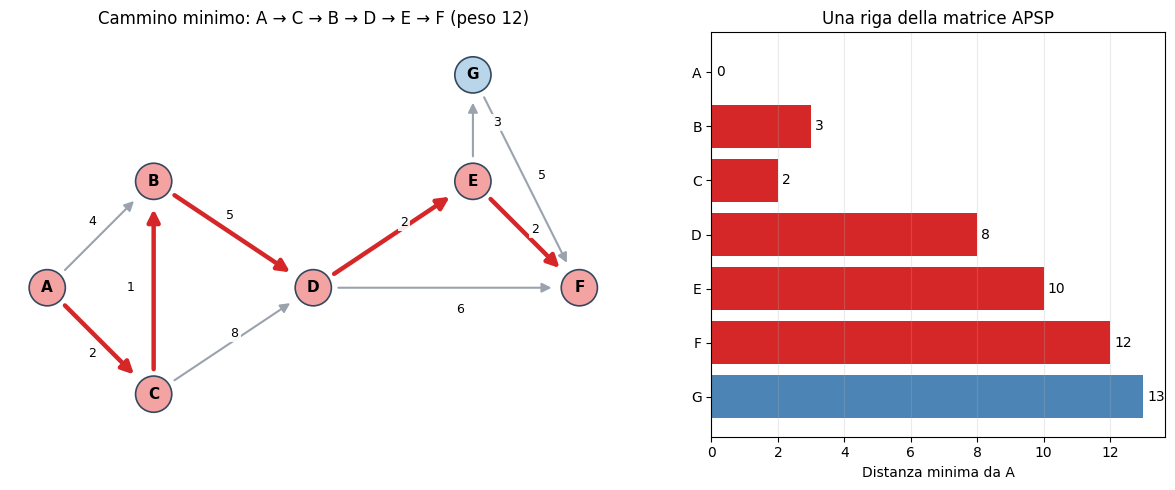

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle

# Grafo diretto piccolo, scelto per rendere leggibile il cammino risultante.
vertices = ["A", "B", "C", "D", "E", "F", "G"]
edges = [("A", "B", 4), ("A", "C", 2), ("C", "B", 1),
         ("B", "D", 5), ("C", "D", 8), ("D", "E", 2),
         ("D", "F", 6), ("E", "F", 2), ("E", "G", 3), ("G", "F", 5)]

n = len(vertices)
index = {name: i for i, name in enumerate(vertices)}
dist = [[float("inf")] * n for _ in range(n)]
next_hop = [[None] * n for _ in range(n)]
for i in range(n):
    dist[i][i] = 0
    next_hop[i][i] = i
for u, v, w in edges:
    i, j = index[u], index[v]
    dist[i][j] = w
    next_hop[i][j] = j

# Floyd–Warshall: aggiorna le distanze e conserva il primo passo del cammino.
for k in range(n):
    for i in range(n):
        for j in range(n):
            candidate = dist[i][k] + dist[k][j]
            if candidate < dist[i][j]:
                dist[i][j] = candidate
                next_hop[i][j] = next_hop[i][k]

source, target = "A", "F"
s, t = index[source], index[target]
path = [s]
while path[-1] != t:
    path.append(next_hop[path[-1]][t])
    if len(path) > n:
        raise RuntimeError("Ricostruzione del cammino non terminata")
path_names = [vertices[i] for i in path]
path_edges = set(zip(path_names[:-1], path_names[1:]))
print(f"Cammino minimo {source} → {target}: {' → '.join(path_names)}")
print(f"Peso totale: {dist[s][t]}")
print("Distanze minime da A:", {v: dist[s][index[v]] for v in vertices})

positions = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2.5, 0),
             "E": (4, 1), "F": (5, 0), "G": (4, 2)}
label_positions = {
    ("A", "B"): (0.42, 0.62), ("A", "C"): (0.42, -0.62),
    ("C", "B"): (0.78, 0.0), ("B", "D"): (1.72, 0.68),
    ("C", "D"): (1.76, -0.43), ("D", "E"): (3.35, 0.61),
    ("D", "F"): (3.88, -0.20), ("E", "F"): (4.58, 0.55),
    ("E", "G"): (4.23, 1.55), ("G", "F"): (4.65, 1.05)
}
fig, (ax_graph, ax_dist) = plt.subplots(1, 2, figsize=(12.5, 5),
                                        gridspec_kw={"width_ratios": [1.6, 1]})

# Disegna archi e pesi, quindi i nodi sopra le frecce.
for u, v, w in edges:
    x1, y1 = positions[u]
    x2, y2 = positions[v]
    on_path = (u, v) in path_edges
    arrow = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                            mutation_scale=18 if on_path else 14,
                            linewidth=3.2 if on_path else 1.5,
                            color="#d62728" if on_path else "#9aa3ad",
                            shrinkA=18, shrinkB=20, zorder=1)
    ax_graph.add_patch(arrow)
    lx, ly = label_positions[(u, v)]
    ax_graph.text(lx, ly, str(w), ha="center", va="center", fontsize=9,
                  bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.9, "pad":1.5},
                  zorder=3)

for v in vertices:
    x, y = positions[v]
    face = "#f4a3a3" if v in path_names else "#b8d5ea"
    ax_graph.add_patch(Circle((x, y), 0.17, facecolor=face,
                              edgecolor="#34495e", linewidth=1.2, zorder=2))
    ax_graph.text(x, y, v, ha="center", va="center", fontsize=11,
                  fontweight="bold", zorder=4)
ax_graph.set_xlim(-0.35, 5.35)
ax_graph.set_ylim(-1.4, 2.4)
ax_graph.set_aspect("equal")
ax_graph.axis("off")
ax_graph.set_title(f"Cammino minimo: {' → '.join(path_names)} (peso {dist[s][t]})")

source_distances = [dist[s][index[v]] for v in vertices]
bar_colors = ["#d62728" if v in path_names else "#4c85b5" for v in vertices]
bars = ax_dist.barh(vertices, source_distances, color=bar_colors)
ax_dist.invert_yaxis()
ax_dist.set_xlabel("Distanza minima da A")
ax_dist.set_title("Una riga della matrice APSP")
ax_dist.grid(axis="x", alpha=0.25)
ax_dist.bar_label(bars, padding=3)
fig.tight_layout()
plt.show()
